In [8]:
from sklearn.feature_extraction.text import CountVectorizer
v = CountVectorizer(ngram_range=(1,3))

v.fit(["Thor Hathodawala is looking for a job"])
v.vocabulary_

{'thor': 12,
 'hathodawala': 2,
 'is': 5,
 'looking': 9,
 'for': 0,
 'job': 8,
 'thor hathodawala': 13,
 'hathodawala is': 3,
 'is looking': 6,
 'looking for': 10,
 'for job': 1,
 'thor hathodawala is': 14,
 'hathodawala is looking': 4,
 'is looking for': 7,
 'looking for job': 11}

In [9]:
corpus = [
    "Thor ate pizza",
    "Loki is tall",
    "Loki is eating pizza"
]

In [17]:
import spacy
nlp = spacy.load("en_core_web_sm")
def preprocessing(text):
    doc = nlp(text)

    filtered_tokens = []

    for token in doc:
        if token.is_stop or token.is_punct:
            continue
        filtered_tokens.append(token.lemma_)
    return " ".join(filtered_tokens)
prepocessing("I ate Pizza")

'eat Pizza'

In [19]:
corpus_processed = [preprocessing(text) for text in corpus]
corpus_processed

['thor eat pizza', 'Loki tall', 'Loki eat pizza']

In [20]:
v = CountVectorizer(ngram_range=(1,2))
v.fit(corpus_processed)
v.vocabulary_

{'thor': 7,
 'eat': 0,
 'pizza': 5,
 'thor eat': 8,
 'eat pizza': 1,
 'loki': 2,
 'tall': 6,
 'loki tall': 4,
 'loki eat': 3}

In [21]:
v.transform(["Thor eat pizza"]).toarray()

array([[0, 0, 0, 0, 0, 1, 0, 1, 0]])

In [22]:
v.transform(["Hulk eat pizza"]).toarray()

array([[1, 1, 0, 0, 0, 1, 0, 0, 0]])

In [24]:
import pandas as pd

df = pd.read_json('news_dataset.json')
print(df.shape)
df.head()

(12695, 2)


,text,category
0,Watching Schrödinger's Cat Die University of C...,SCIENCE
1,WATCH: Freaky Vortex Opens Up In Flooded Lake,SCIENCE
2,Entrepreneurs Today Don't Need a Big Budget to...,BUSINESS
3,These Roads Could Recharge Your Electric Car A...,BUSINESS
4,Civilian 'Guard' Fires Gun While 'Protecting' ...,CRIME


In [26]:
df.category.value_counts()

category
BUSINESS    4254
SPORTS      4167
CRIME       2893
SCIENCE     1381
Name: count, dtype: int64

In [27]:
min_samples = 1381

df_business = df[df.category=='BUSINESS'].sample(min_samples,random_state=1962)
df_business

,text,category
9414,These 5 Companies Are Trying To Spark A Parent...,BUSINESS
1550,"Finally, Someone Got The Best Of Uber The batt...",BUSINESS
4577,Coal Isn’t Just Bad For The Air. It’s A Huge W...,BUSINESS
12317,Leading the Way to Purpose and Profit in Busin...,BUSINESS
3065,Head Of Uber's Self-Driving Car Effort Steps D...,BUSINESS
...,...,...
2832,Are You the Shark in the Pond? It's Time to Fi...,BUSINESS
3104,8 Ways To Get People To Take You More Seriousl...,BUSINESS
1406,Renovation Boom Revives A Deadly Demon For Mas...,BUSINESS
11972,The Soul of Photography I bought my first came...,BUSINESS


In [28]:
df_sports = df[df.category=="SPORTS"].sample(min_samples, random_state=2022)
df_crime = df[df.category=="CRIME"].sample(min_samples, random_state=2022)
df_science = df[df.category=="SCIENCE"].sample(min_samples, random_state=2022)

In [32]:
df_balanced = pd.concat([df_business,df_sports,df_crime,df_science],axis=0)
df_balanced.category.value_counts()

category
BUSINESS    1381
SPORTS      1381
CRIME       1381
SCIENCE     1381
Name: count, dtype: int64

In [33]:
target = {'BUSINESS': 0, 'SPORTS': 1, 'CRIME': 2, 'SCIENCE': 3}

df_balanced['category_num'] = df_balanced['category'].map({
    'BUSINESS': 0,
    'SPORTS': 1, 
    'CRIME': 2, 
    'SCIENCE': 3
})

In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df_balanced.text, 
    df_balanced.category_num, 
    test_size=0.2, # 20% samples will go to test dataset
    random_state=2022,
    stratify=df_balanced.category_num)

In [36]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

clf = Pipeline([
    ('vectorizer_bow',CountVectorizer(ngram_range=(1, 2))),
    ('multinimial',MultinomialNB())
])

clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.70      0.89      0.78       276
           1       0.92      0.75      0.83       277
           2       0.83      0.88      0.85       276
           3       0.93      0.78      0.85       276

    accuracy                           0.83      1105
   macro avg       0.84      0.83      0.83      1105
weighted avg       0.84      0.83      0.83      1105



In [37]:
X_test[:5]

1023     Positive Thinking: A Brief User's Guide Positi...
608      These Cringe-Worthy Stories Show It Can Be Har...
11172    LISTEN: The Accidental Discovery That Proved T...
7005                          10 Best States For Business 
1356     Man Killed By Michigan Police Wasn't Targeting...
Name: text, dtype: object

In [38]:
y_test[:5]

1023     0
608      3
11172    3
7005     0
1356     2
Name: category_num, dtype: int64

In [39]:
y_pred[:5]

array([0, 0, 3, 0, 2])

In [40]:
df_balanced['preprocessed_txt'] = df_balanced.text.apply(preprocessing)
df_balanced.head()


,text,category,category_num,preprocessed_txt
9414,These 5 Companies Are Trying To Spark A Parent...,BUSINESS,0,5 company try spark Parental Leave Revolution ...
1550,"Finally, Someone Got The Best Of Uber The batt...",BUSINESS,0,finally get good Uber battle China Uber lose
4577,Coal Isn’t Just Bad For The Air. It’s A Huge W...,BUSINESS,0,coal bad Air Huge Water Waster coal fire power...
12317,Leading the Way to Purpose and Profit in Busin...,BUSINESS,0,lead way Purpose Profit Business Water Sanitat...
3065,Head Of Uber's Self-Driving Car Effort Steps D...,BUSINESS,0,Head Uber self drive car effort step Anthony L...


In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    df_balanced.preprocessed_txt, 
    df_balanced.category_num, 
    test_size=0.2, # 20% samples will go to test dataset
    random_state=2022,
    stratify=df_balanced.category_num
)

In [42]:
print(X_train.shape)
X_train.head()

(4419,)


7589     ovulate Women prefer Images Penetration Images...
10442     scientist discover Spooky Influence Baby Choices
8792     Olympic Race Walker step Propose boyfriend Rio...
1733     Beloved Bipedal Bear name Pedals believe kill ...
2526       Elizabeth Smart give Birth Baby Girl Father say
Name: preprocessed_txt, dtype: object

In [43]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

clf = Pipeline([
    ('vectorizer_bow',CountVectorizer(ngram_range=(1, 2))),
    ('multinimial',MultinomialNB())
])

clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.88      0.83       276
           1       0.91      0.82      0.86       277
           2       0.83      0.92      0.87       276
           3       0.92      0.82      0.86       276

    accuracy                           0.86      1105
   macro avg       0.86      0.86      0.86      1105
weighted avg       0.86      0.86      0.86      1105



In [44]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
cm

array([[242,  14,  12,   8],
       [ 10, 228,  31,   8],
       [ 16,   2, 254,   4],
       [ 36,   7,   8, 225]])

Text(95.72222222222221, 0.5, 'Truth')

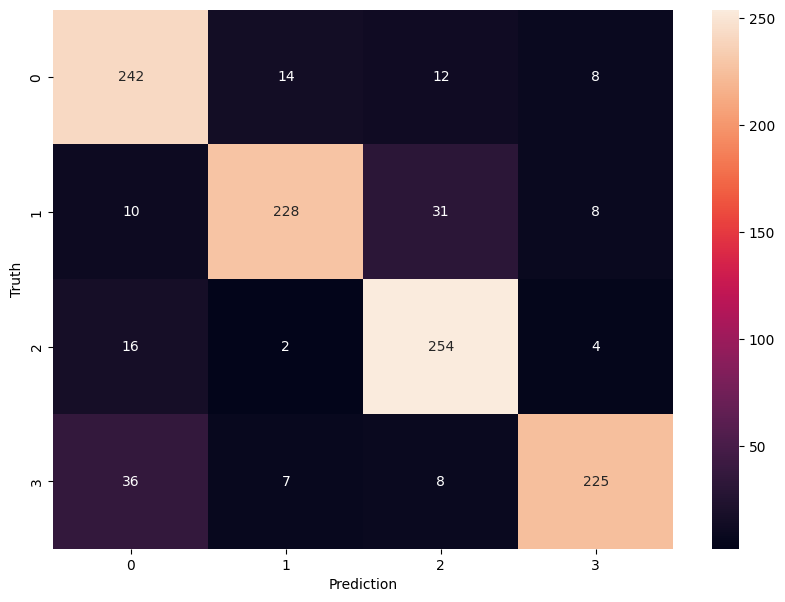

In [45]:
from matplotlib import pyplot as plt
import seaborn as sn
plt.figure(figsize = (10,7))
sn.heatmap(cm, annot=True, fmt='d')
plt.xlabel('Prediction')
plt.ylabel('Truth')